,mean,median,count
event_time,,,
2013-03-01,104.888301,85.0,8881
2013-04-01,62.139109,50.0,8576
2013-05-01,81.846225,69.0,8610
2013-06-01,102.444121,91.0,8420
2013-07-01,67.909378,52.0,8563


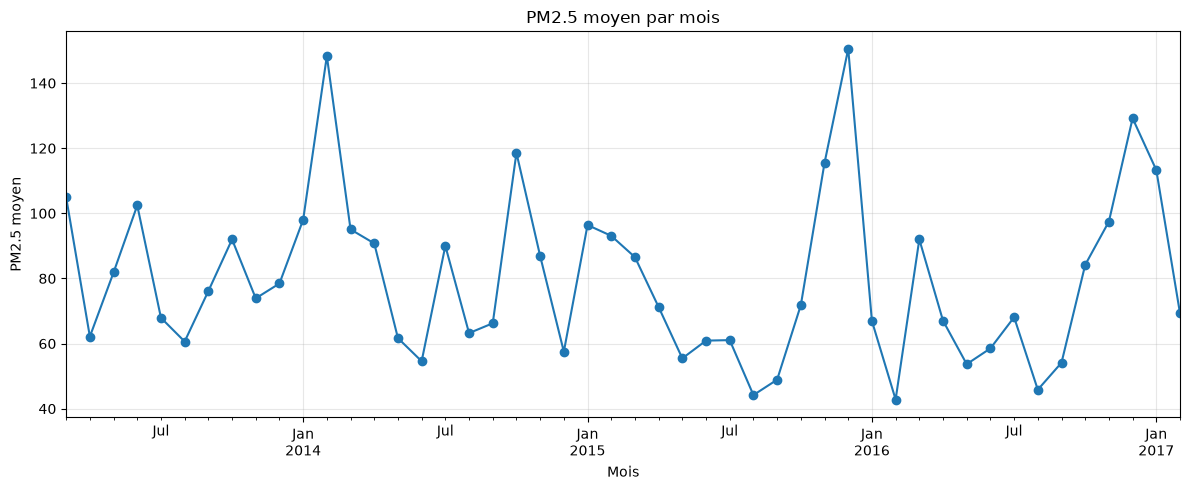

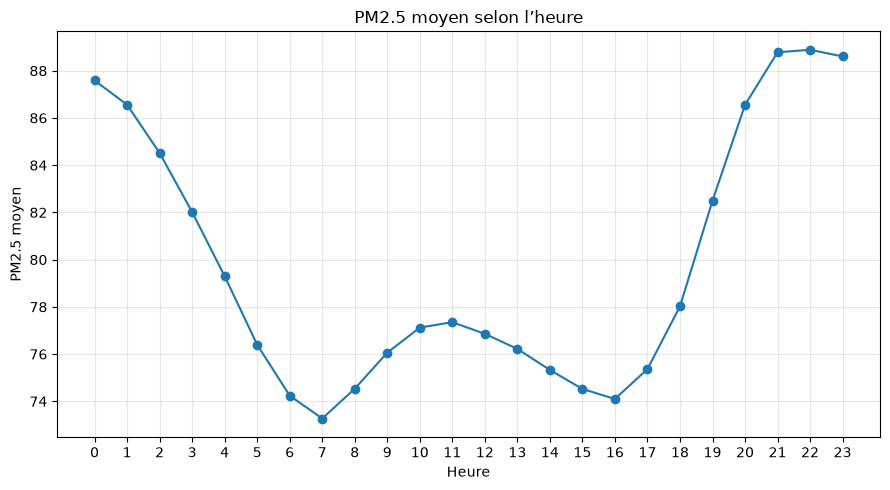

,mean,median,count
season,,,
Automne,82.33,56.0,102746
Hiver,95.48,56.0,101907
Printemps,76.97,58.0,103705
Été,64.67,51.0,103671


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

data_file = Path(
    r"C:\Users\ADMIN\Desktop\AirWatch\analytics\outputs\prepared_data\observations_clean.parquet"
)
df = pd.read_parquet(data_file)

df["event_time"] = pd.to_datetime(df["event_time"], errors="coerce")
df["pm25"] = pd.to_numeric(df["pm25"], errors="coerce")
df = df.dropna(subset=["event_time", "pm25"]).copy()

monthly = (
    df.set_index("event_time")["pm25"]
    .resample("MS")
    .agg(["mean", "median", "count"])
)
display(monthly.head())

monthly["mean"].plot(figsize=(12, 5), marker="o")
plt.title("PM2.5 moyen par mois")
plt.xlabel("Mois")
plt.ylabel("PM2.5 moyen")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

hourly = df.groupby(df["event_time"].dt.hour)["pm25"].mean()
hourly.plot(figsize=(9, 5), marker="o")
plt.title("PM2.5 moyen selon l’heure")
plt.xlabel("Heure")
plt.ylabel("PM2.5 moyen")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

seasons = {
    12: "Hiver", 1: "Hiver", 2: "Hiver",
    3: "Printemps", 4: "Printemps", 5: "Printemps",
    6: "Été", 7: "Été", 8: "Été",
    9: "Automne", 10: "Automne", 11: "Automne",
}
df["season"] = df["event_time"].dt.month.map(seasons)

seasonal = df.groupby("season")["pm25"].agg(["mean", "median", "count"])
display(seasonal.round(2))